# Anchor component isolation test

Pass a video path once, then run **each Layer-0 detector in its own cell** to see which one floods cues.

1. Set `VIDEO_PATH` in the setup cell and run it.
2. Run any component cell independently (or Run All).
3. Scroll to **Noise ranking** at the bottom to compare densities.

| Component | Source file |
|---|---|
| `onsets_v1` | `perception/onsets.py` |
| `onsets_v2` | `perception/onsets_v2.py` |
| `onsets_v2_effects` | `onsets_v2.py` + `separation.py` |
| `intensity_change` | `perception/video_cues.py` |
| `video_cues` | `perception/video_cues.py` |
| `scenes` | `perception/scenes.py` |
| `speech` | `perception/speech.py` |
| `sed` | `perception/sed/*` |
| `beats` | `perception/beats.py` |
| `fusion` | `perception/anchors.py` |

## 0 — Setup (edit `VIDEO_PATH`, then run)

In [5]:
from __future__ import annotations

import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

%matplotlib inline

In [6]:



def _find_repo_root() -> Path:
    here = Path.cwd().resolve()
    for c in [here, *here.parents, (here / "..").resolve(), (here / "../..").resolve()]:
        if (c / "Dataset" / "raw_videos").is_dir() and (c / "dataset_generating_pipepline").is_dir():
            return c
    return here


REPO_ROOT = _find_repo_root()
PIPELINE_DIR = REPO_ROOT / "dataset_generating_pipepline"
if str(PIPELINE_DIR) not in sys.path:
    sys.path.insert(0, str(PIPELINE_DIR))

# ─── change this path ───────────────────────────────────────────────
VIDEO_PATH = REPO_ROOT / "Dataset" / "raw_videos" / "nq1M_Wc4FIc" / "clip_000.mp4"
# VIDEO_PATH = REPO_ROOT / "Dataset" / "raw_videos" / "JKa05nyUmuQ" / "clip_003.mp4"
# ─────────────────────────────────────────────────────────────────────

LEVEL = "high"                 # "low" | "high" (affects fusion / onset cfg)
MIN_INTENSITY_CHANGE = 5.0     # notebook-style |Δ| threshold
USE_FARNEBACK = False          # True = slower, denser motion cues
MAD_K = None                   # e.g. 6.5 to harden onsets_v2; None = config default
SAVE_LABELS = True             # write Audacity .txt next to the video

assert VIDEO_PATH.is_file(), f"missing video: {VIDEO_PATH}"
print("REPO_ROOT:", REPO_ROOT)
print("VIDEO_PATH:", VIDEO_PATH)
print("exists:", VIDEO_PATH.is_file())

REPO_ROOT: /Users/ajitesh/Desktop/VisualMellow/Youtube_dataset_generation_pipeline
VIDEO_PATH: /Users/ajitesh/Desktop/VisualMellow/Youtube_dataset_generation_pipeline/Dataset/raw_videos/nq1M_Wc4FIc/clip_000.mp4
exists: True


In [7]:
from tools.diagnose_anchors import (
    COMPONENT_SOURCES,
    density_stats,
    run_beats,
    run_fusion,
    run_intensity_change,
    run_onsets_v1,
    run_onsets_v2,
    run_onsets_v2_effects,
    run_scenes,
    run_sed,
    run_speech,
    run_video_cues,
    write_audacity,
)
from perception.audio_io import decode_dsp, decode_mono
from perception.timebase import probe
from core.config import load_pipeline_config

meta = probe(VIDEO_PATH)
DURATION_MS = int(meta.get("duration_ms") or round(float(meta.get("duration") or 0) * 1000))
print(f"duration={DURATION_MS}ms  fps={meta.get('fps')}  size={meta.get('width')}x{meta.get('height')}")

print("decoding audio…")
AUDIO16 = decode_mono(VIDEO_PATH, sample_rate=16000)
AUDIO32 = decode_dsp(VIDEO_PATH, sample_rate=32000)
SR16, SR32 = 16000, 32000
DURATION_MS = max(DURATION_MS, int(round(len(AUDIO16) / SR16 * 1000)))
print(f"audio16={AUDIO16.shape}  audio32={AUDIO32.shape}  duration_ms={DURATION_MS}")

cfg = load_pipeline_config(LEVEL)
OV2_CFG = cfg.perception.onsets_v2.as_dict()
if MAD_K is not None:
    OV2_CFG["mad_k"] = float(MAD_K)

OUT_DIR = VIDEO_PATH.with_name(VIDEO_PATH.stem + "_anchor_diag_nb")
if SAVE_LABELS:
    OUT_DIR.mkdir(parents=True, exist_ok=True)

# Collect results from whichever cells you run
RESULTS: dict[str, dict] = {}


def show_component(name: str, events: list[dict]) -> pd.DataFrame:
    """Print density stats, store in RESULTS, optional Audacity labels, return event table."""
    stats = density_stats(events, DURATION_MS)
    by_kind: dict[str, int] = {}
    for e in events:
        by_kind[str(e.get("kind"))] = by_kind.get(str(e.get("kind")), 0) + 1
    RESULTS[name] = {"events": events, "stats": stats, "by_kind": by_kind, "source": COMPONENT_SOURCES.get(name, "?")}
    if SAVE_LABELS:
        write_audacity(OUT_DIR / f"{name}.txt", events)

    print(f"=== {name}  ← {COMPONENT_SOURCES.get(name, '?')} ===")
    print(
        f"n={stats['n']}  per_sec={stats['per_sec']}  "
        f"median_gap_ms={stats['median_gap_ms']}  noise_score={stats['noise_score']}"
    )
    print("by_kind:", by_kind)
    if SAVE_LABELS:
        print("labels →", OUT_DIR / f"{name}.txt")

    rows = []
    for e in sorted(events, key=lambda x: float(x.get("t_ms_f", x.get("t_ms", 0)) or 0)):
        rows.append({
            "t_s": round(float(e.get("t_ms_f", e.get("t_ms", 0)) or 0) / 1000.0, 3),
            "kind": e.get("kind"),
            "strength": e.get("strength"),
            "label": e.get("label"),
        })
    df = pd.DataFrame(rows)
    return df


def plot_timeline(name: str, events: list[dict] | None = None, *, max_points: int = 800):
    ev = events if events is not None else RESULTS.get(name, {}).get("events", [])
    if not ev:
        print("(no events)")
        return
    times = np.array([float(e.get("t_ms_f", e.get("t_ms", 0)) or 0) / 1000.0 for e in ev])
    strengths = np.array([float(e.get("strength") or 1.0) for e in ev])
    if len(times) > max_points:
        idx = np.linspace(0, len(times) - 1, max_points).astype(int)
        times, strengths = times[idx], strengths[idx]
    fig, ax = plt.subplots(figsize=(12, 2.2))
    ax.vlines(times, 0, strengths, colors="C0", alpha=0.7, linewidth=0.8)
    ax.set_xlim(0, DURATION_MS / 1000.0)
    ax.set_xlabel("time (s)")
    ax.set_ylabel("strength")
    ax.set_title(f"{name}  (n={len(ev)})")
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()


print("helpers ready. Run any component cell below.")
print("sources:")
for k, v in COMPONENT_SOURCES.items():
    print(f"  {k:22s}  {v}")

duration=30030ms  fps=29.97002997002997  size=640x360
decoding audio…
audio16=(480003,)  audio32=(960006,)  duration_ms=30030
helpers ready. Run any component cell below.
sources:
  onsets_v1               perception/onsets.py
  onsets_v2               perception/onsets_v2.py
  onsets_v2_effects       perception/onsets_v2.py + perception/separation.py
  intensity_change        perception/video_cues.py::detect_intensity_changes
  video_cues              perception/video_cues.py
  scenes                  perception/scenes.py
  speech                  perception/speech.py
  sed                     perception/sed/{backend,infer,events,ontology}.py
  beats                   perception/beats.py
  fusion                  perception/anchors.py


## 1 — `onsets_v1` → `perception/onsets.py`

=== onsets_v1  ← perception/onsets.py ===
n=26  per_sec=0.87  median_gap_ms=440.0  noise_score=0.0
by_kind: {'audio_onset': 26}
labels → /Users/ajitesh/Desktop/VisualMellow/Youtube_dataset_generation_pipeline/Dataset/raw_videos/nq1M_Wc4FIc/clip_000_anchor_diag_nb/onsets_v1.txt


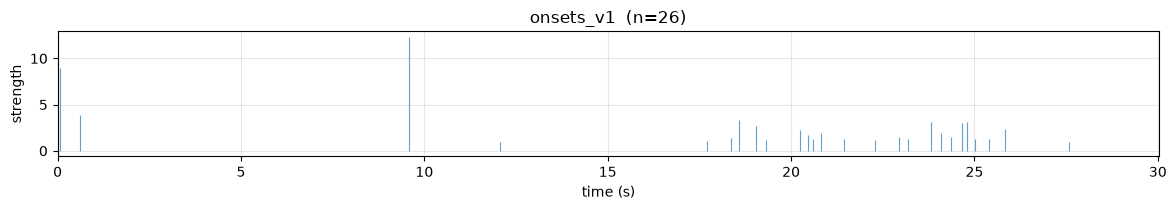

,t_s,kind,strength,label
0,0.07,audio_onset,8.951067,audio_onset|mixture
1,0.61,audio_onset,3.888531,audio_onset|mixture
2,9.57,audio_onset,12.315597,audio_onset|mixture
3,12.06,audio_onset,0.932557,audio_onset|mixture
4,17.70,audio_onset,1.093865,audio_onset|mixture
5,18.35,audio_onset,1.371751,audio_onset|mixture
6,18.58,audio_onset,3.334510,audio_onset|mixture
7,19.04,audio_onset,2.726599,audio_onset|mixture
8,19.31,audio_onset,1.221108,audio_onset|mixture
9,20.24,audio_onset,2.291015,audio_onset|mixture


In [8]:
ev = run_onsets_v1(AUDIO16, SR16)
df = show_component("onsets_v1", ev)
plot_timeline("onsets_v1", ev)
df.head(40)

## 2 — `onsets_v2` → `perception/onsets_v2.py`

Usually the densest mixture-onset detector. Tweak `MAD_K` in setup or override `OV2_CFG` here.

=== onsets_v2  ← perception/onsets_v2.py ===
n=360  per_sec=11.99  median_gap_ms=59.7  noise_score=0.453
by_kind: {'audio_onset': 360}
labels → /Users/ajitesh/Desktop/VisualMellow/Youtube_dataset_generation_pipeline/Dataset/raw_videos/nq1M_Wc4FIc/clip_000_anchor_diag_nb/onsets_v2.txt


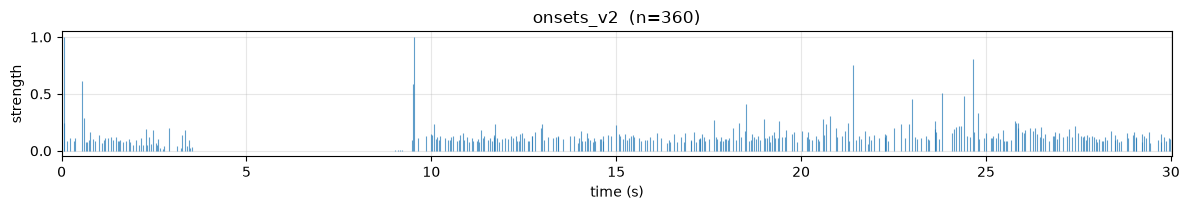

,t_s,kind,strength,label
0,0.059,audio_onset,1.000000,audio_onset|mixture|hf+lf+lowmid+mid
1,0.060,audio_onset,0.247870,audio_onset|mixture|lf
2,0.150,audio_onset,0.084045,audio_onset|mixture|hf
3,0.230,audio_onset,0.116064,audio_onset|mixture|hf+lf+lowmid
4,0.330,audio_onset,0.081988,audio_onset|mixture|mid
5,0.370,audio_onset,0.115218,audio_onset|mixture|lf+lowmid
6,0.563,audio_onset,0.614815,audio_onset|mixture|hf+lf+lowmid+mid
7,0.612,audio_onset,0.284882,audio_onset|mixture|lf+lowmid+mid
8,0.660,audio_onset,0.079243,audio_onset|mixture|mid
9,0.685,audio_onset,0.078753,audio_onset|mixture|lowmid


In [9]:
# Optional local override (uncomment):
# OV2_CFG = {**OV2_CFG, "mad_k": 6.5, "min_gap_ms": 80}

ev = run_onsets_v2(AUDIO32, SR32, cfg_dict=OV2_CFG)
df = show_component("onsets_v2", ev)
plot_timeline("onsets_v2", ev)
df.head(40)

## 3 — `onsets_v2_effects` → Demucs effects stem + `onsets_v2`

Often the **noisiest** (effects stem is sparse/noisy → SuperFlux fires constantly).

=== onsets_v2_effects  ← perception/onsets_v2.py + perception/separation.py ===
n=619  per_sec=20.61  median_gap_ms=45.0  noise_score=1.0
by_kind: {'audio_onset': 619}
labels → /Users/ajitesh/Desktop/VisualMellow/Youtube_dataset_generation_pipeline/Dataset/raw_videos/nq1M_Wc4FIc/clip_000_anchor_diag_nb/onsets_v2_effects.txt


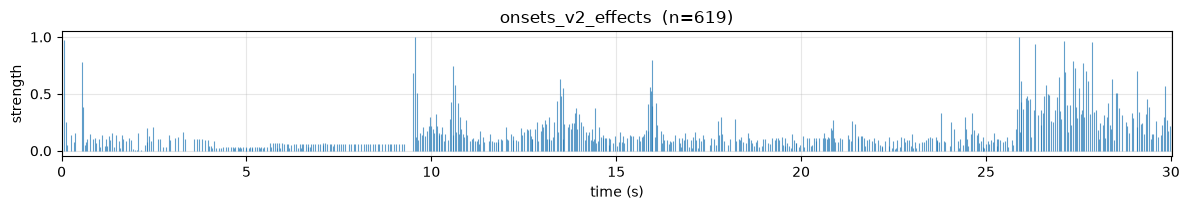

,t_s,kind,strength,label
0,0.060,audio_onset,0.972135,audio_onset|effects|hf+lf+lowmid+mid
1,0.122,audio_onset,0.253199,audio_onset|effects|hf+lf+mid
2,0.150,audio_onset,0.050888,audio_onset|effects|hf
3,0.255,audio_onset,0.138201,audio_onset|effects|hf+lf+lowmid
4,0.330,audio_onset,0.081170,audio_onset|effects|hf+mid
5,0.370,audio_onset,0.157742,audio_onset|effects|lowmid
6,0.563,audio_onset,0.778168,audio_onset|effects|hf+lf+lowmid+mid
7,0.582,audio_onset,0.388072,audio_onset|effects|hf+lf+lowmid+mid
8,0.620,audio_onset,0.049077,audio_onset|effects|hf
9,0.660,audio_onset,0.073698,audio_onset|effects|hf+mid


In [10]:
ev = run_onsets_v2_effects(AUDIO16, SR16, AUDIO32, SR32, cfg_dict=OV2_CFG)
df = show_component("onsets_v2_effects", ev)
plot_timeline("onsets_v2_effects", ev)
df.head(40)

## 4 — `intensity_change` → `perception/video_cues.py::detect_intensity_changes`

Mean pixel `|Δ| ≥ MIN_INTENSITY_CHANGE` (default 5).

=== intensity_change  ← perception/video_cues.py::detect_intensity_changes ===
n=32  per_sec=1.07  median_gap_ms=250.3  noise_score=0.0
by_kind: {'intensity_change': 32}
labels → /Users/ajitesh/Desktop/VisualMellow/Youtube_dataset_generation_pipeline/Dataset/raw_videos/nq1M_Wc4FIc/clip_000_anchor_diag_nb/intensity_change.txt


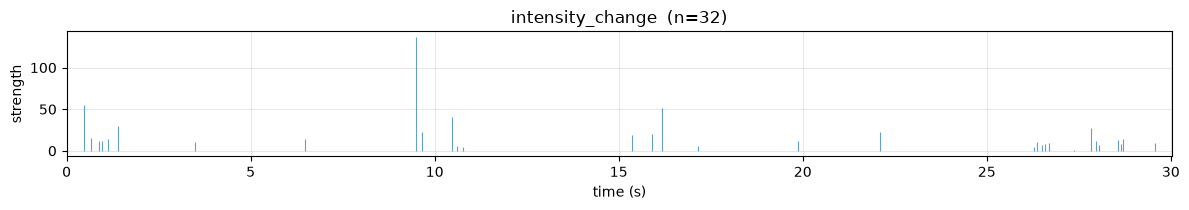

,t_s,kind,strength,label
0,0.484,intensity_change,55.38,intensity_change|down|d-55.38
1,0.667,intensity_change,14.86,intensity_change|up|d14.86
2,0.868,intensity_change,11.31,intensity_change|up|d11.31
3,0.968,intensity_change,11.92,intensity_change|up|d11.92
4,1.135,intensity_change,14.71,intensity_change|down|d-14.71
5,1.401,intensity_change,30.34,intensity_change|down|d-30.34
6,3.487,intensity_change,10.26,intensity_change|down|d-10.26
7,6.490,intensity_change,14.02,intensity_change|up|d14.02
8,9.493,intensity_change,136.74,intensity_change|up|d136.74
9,9.660,intensity_change,22.47,intensity_change|down|d-22.47


In [11]:
ev = run_intensity_change(VIDEO_PATH, min_change=MIN_INTENSITY_CHANGE)
df = show_component("intensity_change", ev)
plot_timeline("intensity_change", ev)
df.head(40)

## 5 — `video_cues` → `perception/video_cues.py` (full v2: cut / motion / flash / intensity)

=== video_cues  ← perception/video_cues.py ===
n=78  per_sec=2.6  median_gap_ms=38.9  noise_score=0.514
by_kind: {'cut': 14, 'motion_spike': 12, 'motion_stop': 11, 'flash': 9, 'intensity_change': 32}
labels → /Users/ajitesh/Desktop/VisualMellow/Youtube_dataset_generation_pipeline/Dataset/raw_videos/nq1M_Wc4FIc/clip_000_anchor_diag_nb/video_cues.txt


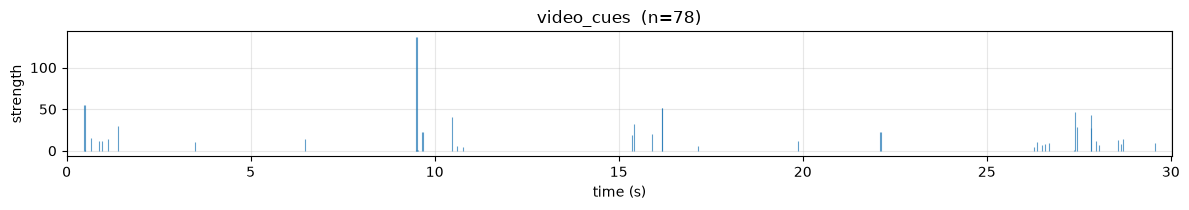

,t_s,kind,strength,label
0,0.484,intensity_change,55.382500,intensity_change|down|d-55.38
1,0.495,motion_spike,0.372584,motion_spike
2,0.500,flash,55.382500,flash
3,0.501,cut,0.217186,cut
4,0.539,motion_stop,0.366874,motion_stop
5,0.667,intensity_change,14.859931,intensity_change|up|d14.86
6,0.868,intensity_change,11.308125,intensity_change|up|d11.31
7,0.968,intensity_change,11.921875,intensity_change|up|d11.92
8,1.135,intensity_change,14.710972,intensity_change|down|d-14.71
9,1.401,intensity_change,30.342708,intensity_change|down|d-30.34


In [12]:
ev = run_video_cues(VIDEO_PATH, min_change=MIN_INTENSITY_CHANGE, use_farneback=USE_FARNEBACK)
df = show_component("video_cues", ev)
plot_timeline("video_cues", ev)
df.head(40)

## 6 — `scenes` → `perception/scenes.py`

=== scenes  ← perception/scenes.py ===
n=18  per_sec=0.6  median_gap_ms=1733.0  noise_score=0.0
by_kind: {'cut': 4, 'motion': 14}
labels → /Users/ajitesh/Desktop/VisualMellow/Youtube_dataset_generation_pipeline/Dataset/raw_videos/nq1M_Wc4FIc/clip_000_anchor_diag_nb/scenes.txt


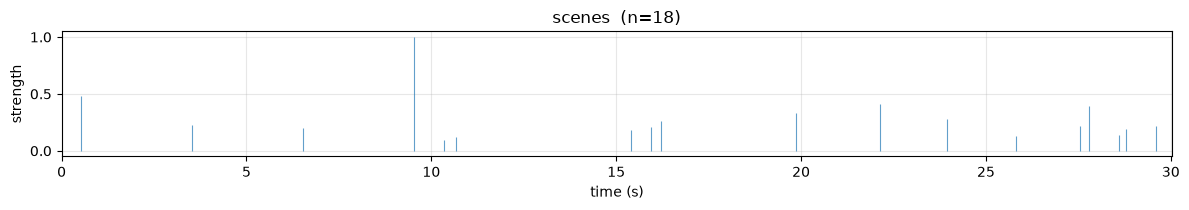

,t_s,kind,strength,label
0,0.533,cut,0.479608,cut
1,3.533,motion,0.227408,motion
2,6.533,motion,0.202964,motion
3,9.533,cut,1.000000,cut
4,10.333,motion,0.093683,motion
5,10.667,motion,0.118131,motion
6,15.400,motion,0.182963,motion
7,15.933,motion,0.210321,motion
8,16.200,motion,0.263487,motion
9,19.867,motion,0.328918,motion


In [13]:
ev = run_scenes(VIDEO_PATH)
df = show_component("scenes", ev)
plot_timeline("scenes", ev)
df.head(40)

## 7 — `beats` → `perception/beats.py`

Support grid only (not SFX cue anchors).

=== beats  ← perception/beats.py ===
n=55  per_sec=1.83  median_gap_ms=480.0  noise_score=0.0
by_kind: {'beat': 55}
labels → /Users/ajitesh/Desktop/VisualMellow/Youtube_dataset_generation_pipeline/Dataset/raw_videos/nq1M_Wc4FIc/clip_000_anchor_diag_nb/beats.txt


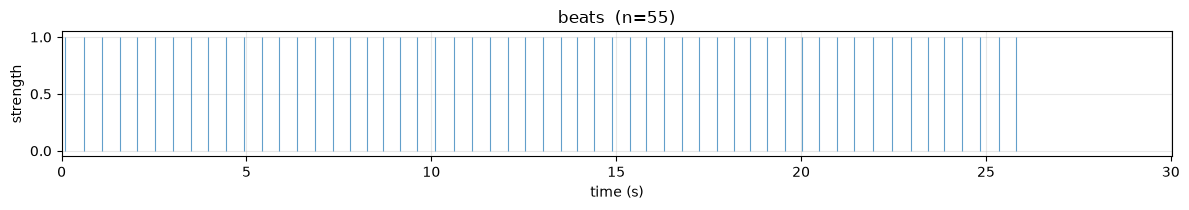

,t_s,kind,strength,label
0,0.096,beat,1.0,beat
1,0.608,beat,1.0,beat
2,1.088,beat,1.0,beat
3,1.568,beat,1.0,beat
4,2.048,beat,1.0,beat
5,2.528,beat,1.0,beat
6,3.008,beat,1.0,beat
7,3.488,beat,1.0,beat
8,3.968,beat,1.0,beat
9,4.448,beat,1.0,beat


In [14]:
ev = run_beats(AUDIO16, SR16)
df = show_component("beats", ev)
plot_timeline("beats", ev)
df.head(40)

## 8 — `speech` → `perception/speech.py` (Whisper — slower)

objc[16482]: Class AVFFrameReceiver is implemented in both /Users/ajitesh/Desktop/VisualMellow/Youtube_dataset_generation_pipeline/.venv/lib/python3.12/site-packages/cv2/.dylibs/libavdevice.61.3.100.dylib (0x137c603a8) and /Users/ajitesh/Desktop/VisualMellow/Youtube_dataset_generation_pipeline/.venv/lib/python3.12/site-packages/av/.dylibs/libavdevice.63.1.102.dylib (0x145dbc3a8). This may cause spurious casting failures and mysterious crashes. One of the duplicates must be removed or renamed.
objc[16482]: Class AVFAudioReceiver is implemented in both /Users/ajitesh/Desktop/VisualMellow/Youtube_dataset_generation_pipeline/.venv/lib/python3.12/site-packages/cv2/.dylibs/libavdevice.61.3.100.dylib (0x137c603f8) and /Users/ajitesh/Desktop/VisualMellow/Youtube_dataset_generation_pipeline/.venv/lib/python3.12/site-packages/av/.dylibs/libavdevice.63.1.102.dylib (0x145dbc3f8). This may cause spurious casting failures and mysterious crashes. One of the duplicates must be removed or renamed.


=== speech  ← perception/speech.py ===
n=2  per_sec=0.07  median_gap_ms=3330.0  noise_score=0.0
by_kind: {'speech_start': 2}
labels → /Users/ajitesh/Desktop/VisualMellow/Youtube_dataset_generation_pipeline/Dataset/raw_videos/nq1M_Wc4FIc/clip_000_anchor_diag_nb/speech.txt


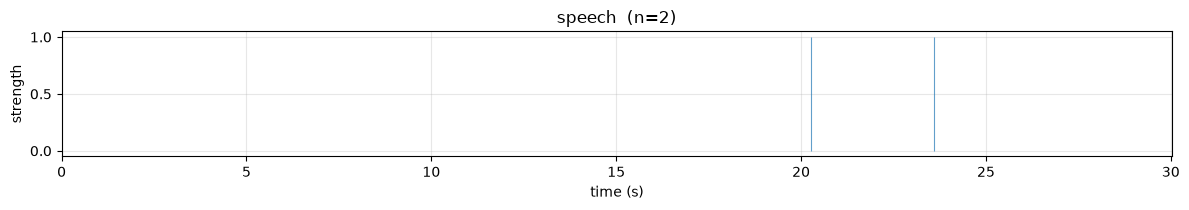

,t_s,kind,strength,label
0,20.27,speech_start,None,speech_start
1,23.60,speech_start,None,speech_start


In [15]:
ev = run_speech(AUDIO16, SR16)
df = show_component("speech", ev)
plot_timeline("speech", ev)
df.head(40)

## 9 — `sed` → `perception/sed/*` (optional / slower)

Checkpoint path: /Users/ajitesh/panns_data/Cnn14_DecisionLevelMax.pth


sh: wget: command not found
SoundEventDetection unavailable ([Errno 2] No such file or directory: '/Users/ajitesh/panns_data/Cnn14_DecisionLevelMax.pth'); using AudioTagging windows


Checkpoint path: /Users/ajitesh/panns_data/Cnn14_mAP=0.431.pth
Using CPU.
=== sed  ← perception/sed/{backend,infer,events,ontology}.py ===
n=14  per_sec=0.47  median_gap_ms=1800.0  noise_score=0.0
by_kind: {'sed_event': 14}
labels → /Users/ajitesh/Desktop/VisualMellow/Youtube_dataset_generation_pipeline/Dataset/raw_videos/nq1M_Wc4FIc/clip_000_anchor_diag_nb/sed.txt


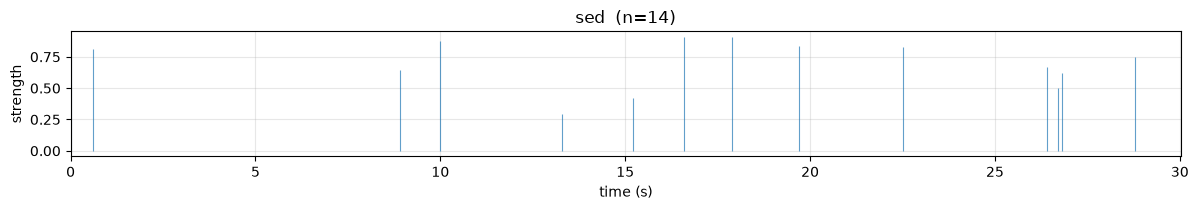

,t_s,kind,strength,label
0,0.019,sed_event,0.900731,sed_event
1,0.600,sed_event,0.810335,sed_event
2,8.900,sed_event,0.643245,sed_event
3,10.000,sed_event,0.876837,sed_event
4,13.300,sed_event,0.296918,sed_event
5,15.200,sed_event,0.420987,sed_event
6,16.600,sed_event,0.908105,sed_event
7,17.900,sed_event,0.905248,sed_event
8,19.700,sed_event,0.835380,sed_event
9,22.500,sed_event,0.829552,sed_event


In [16]:
ev = run_sed(AUDIO16, SR16, AUDIO32, SR32)
df = show_component("sed", ev)
plot_timeline("sed", ev)
df.head(40)

## 10 — `fusion` → `perception/anchors.py` (full merged timeline)

Runs the real Layer-0 builder — slowest. Compare this to the isolated cells above.

Checkpoint path: /Users/ajitesh/panns_data/Cnn14_mAP=0.431.pth
Using CPU.
Checkpoint path: /Users/ajitesh/panns_data/Cnn14_DecisionLevelMax.pth


sh: wget: command not found
SoundEventDetection unavailable ([Errno 2] No such file or directory: '/Users/ajitesh/panns_data/Cnn14_DecisionLevelMax.pth'); using AudioTagging windows


Checkpoint path: /Users/ajitesh/panns_data/Cnn14_mAP=0.431.pth
Using CPU.


Estimated A/V offset -270.0 ms (confidence=0.62) — warn only unless apply flag set


=== fusion  ← perception/anchors.py ===
n=430  per_sec=14.32  median_gap_ms=66.1  noise_score=0.49
by_kind: {'sed_event': 10, 'audio_onset': 418, 'speech_start': 2}
labels → /Users/ajitesh/Desktop/VisualMellow/Youtube_dataset_generation_pipeline/Dataset/raw_videos/nq1M_Wc4FIc/clip_000_anchor_diag_nb/fusion.txt


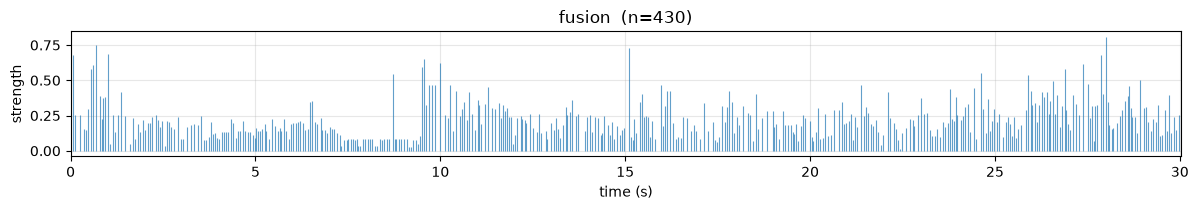

,t_s,kind,strength,label
0,0.060,sed_event,0.680786,sed_event|effects
1,0.122,audio_onset,0.255288,audio_onset|music
2,0.255,audio_onset,0.251023,audio_onset|music
3,0.370,audio_onset,0.152300,audio_onset|music
4,0.425,audio_onset,0.144195,audio_onset|dialogue
5,0.470,audio_onset,0.299929,audio_onset|dialogue
6,0.563,audio_onset,0.580436,audio_onset|effects
7,0.612,sed_event,0.609975,sed_event|effects
8,0.690,sed_event,0.753237,sed_event|effects
9,0.795,sed_event,0.385293,sed_event|effects


In [17]:
ev = run_fusion(VIDEO_PATH, level=LEVEL)
df = show_component("fusion", ev)
plot_timeline("fusion", ev)
df.head(40)

## Noise ranking

Re-run this cell after you’ve executed the component cells you care about.

Highest noise first — fix from the top:


,component,n,per_sec,median_gap_ms,noise_score,by_kind,source
1,onsets_v2_effects,619,20.61,45.0,1.000,{'audio_onset': 619},perception/onsets_v2.py + perception/separatio...
2,video_cues,78,2.60,38.9,0.514,"{'cut': 14, 'motion_spike': 12, 'motion_stop':...",perception/video_cues.py
3,fusion,430,14.32,66.1,0.490,"{'sed_event': 10, 'audio_onset': 418, 'speech_...",perception/anchors.py
4,onsets_v2,360,11.99,59.7,0.453,{'audio_onset': 360},perception/onsets_v2.py
5,onsets_v1,26,0.87,440.0,0.000,{'audio_onset': 26},perception/onsets.py
6,intensity_change,32,1.07,250.3,0.000,{'intensity_change': 32},perception/video_cues.py::detect_intensity_cha...
7,scenes,18,0.60,1733.0,0.000,"{'cut': 4, 'motion': 14}",perception/scenes.py
8,beats,55,1.83,480.0,0.000,{'beat': 55},perception/beats.py
9,speech,2,0.07,3330.0,0.000,{'speech_start': 2},perception/speech.py
10,sed,14,0.47,1800.0,0.000,{'sed_event': 14},"perception/sed/{backend,infer,events,ontology}.py"


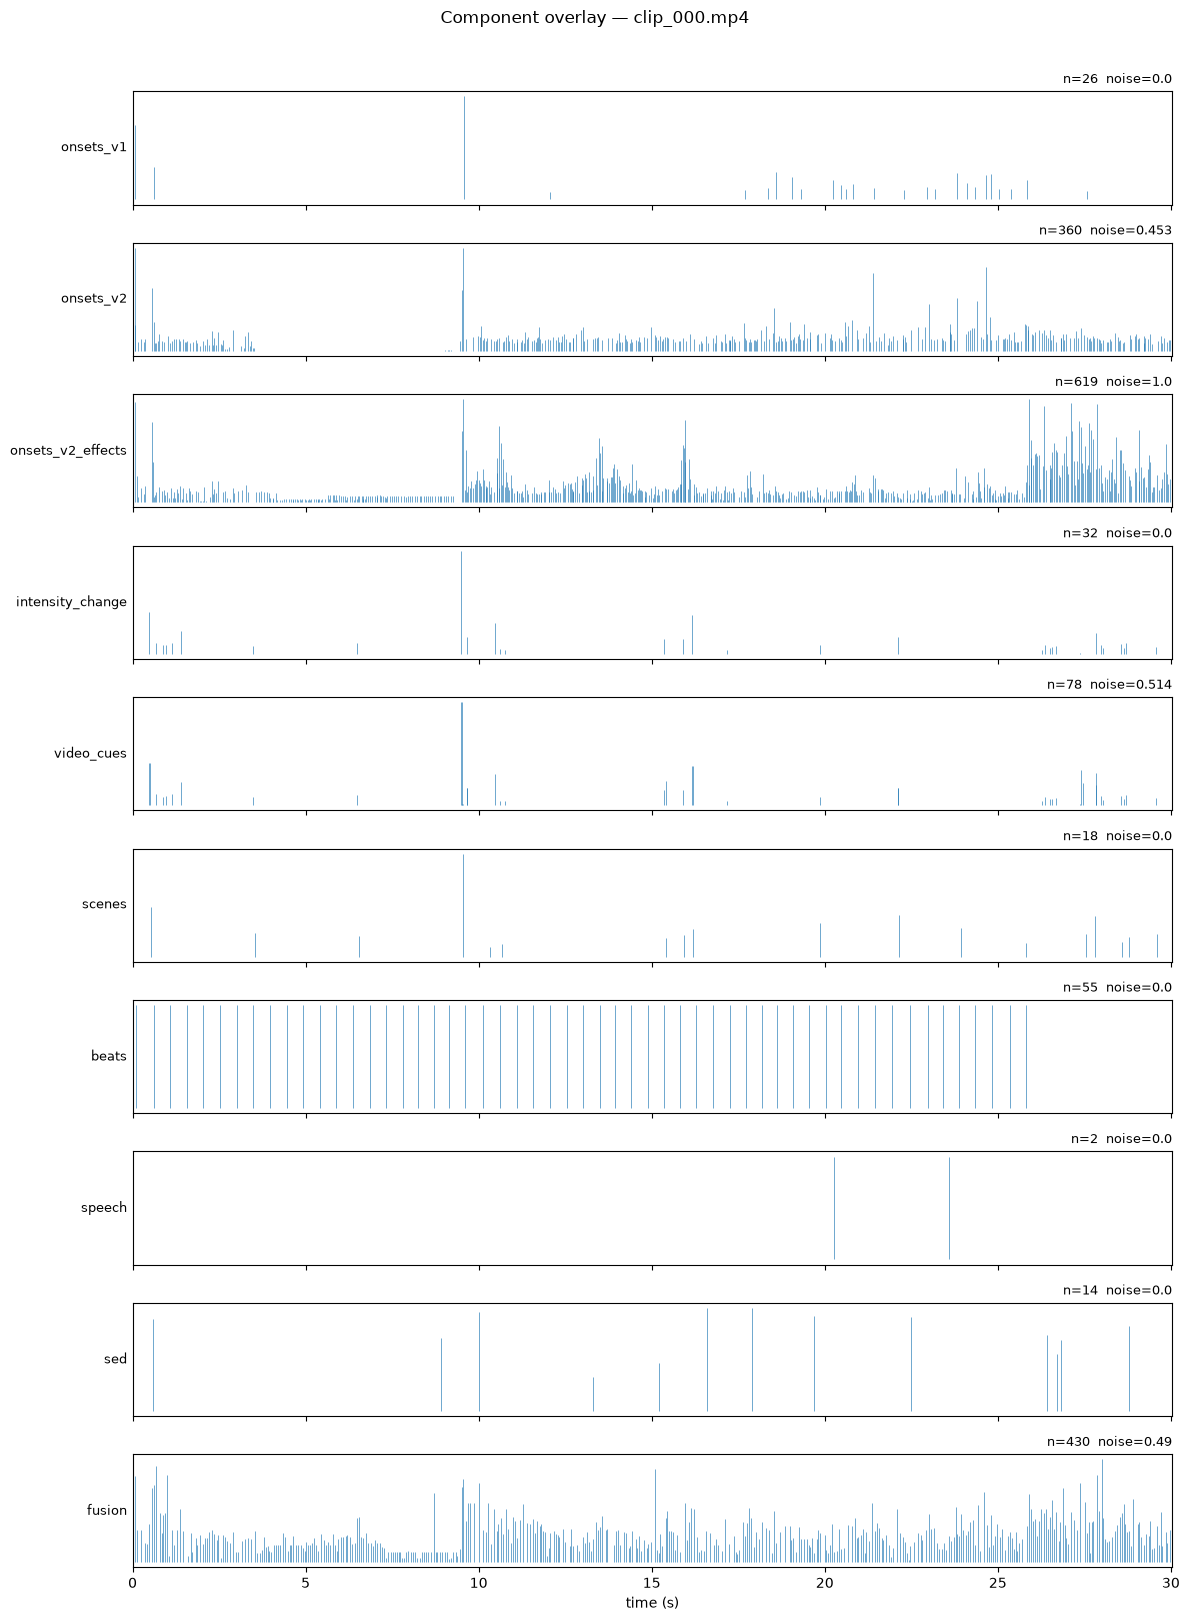

Audacity labels: /Users/ajitesh/Desktop/VisualMellow/Youtube_dataset_generation_pipeline/Dataset/raw_videos/nq1M_Wc4FIc/clip_000_anchor_diag_nb


In [18]:
if not RESULTS:
    print("No components run yet — execute some cells above first.")
else:
    rows = []
    for name, payload in RESULTS.items():
        s = payload["stats"]
        rows.append({
            "component": name,
            "n": s["n"],
            "per_sec": s["per_sec"],
            "median_gap_ms": s["median_gap_ms"],
            "noise_score": s["noise_score"],
            "by_kind": payload["by_kind"],
            "source": payload["source"],
        })
    rank = pd.DataFrame(rows).sort_values("noise_score", ascending=False).reset_index(drop=True)
    rank.index = rank.index + 1
    print("Highest noise first — fix from the top:")
    display(rank)

    # Overlay all run components on one timeline
    names = list(RESULTS.keys())
    fig, axes = plt.subplots(len(names), 1, figsize=(12, 1.6 * len(names)), sharex=True)
    if len(names) == 1:
        axes = [axes]
    for ax, name in zip(axes, names):
        ev = RESULTS[name]["events"]
        times = [float(e.get("t_ms_f", e.get("t_ms", 0)) or 0) / 1000.0 for e in ev]
        strengths = [float(e.get("strength") or 1.0) for e in ev]
        ax.vlines(times, 0, strengths, colors="C0", alpha=0.65, linewidth=0.7)
        ax.set_ylabel(name, rotation=0, ha="right", va="center", fontsize=9)
        ax.set_yticks([])
        ax.set_xlim(0, DURATION_MS / 1000.0)
        n = RESULTS[name]["stats"]["n"]
        ax.set_title(f"n={n}  noise={RESULTS[name]['stats']['noise_score']}", loc="right", fontsize=9)
    axes[-1].set_xlabel("time (s)")
    fig.suptitle(f"Component overlay — {VIDEO_PATH.name}", y=1.01)
    plt.tight_layout()
    plt.show()

    if SAVE_LABELS:
        print("Audacity labels:", OUT_DIR)